In [1]:
# 目的: CRITEO-UPLIFTv2を読み込み、行数・列・先頭行を確認する。
import pandas as pd

file_path = "../0.data/criteo-uplift-v2.1.csv"

df = pd.read_csv(file_path)

print(df.shape)
print(df.columns.tolist())

# 目的: 特徴量と処置・outcomeの実データ例を目視する。
df.sample(n = 5)

(13979592, 16)
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
1606812,26.484909,10.059654,8.214383,4.679882,10.280525,4.115453,-1.288207,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
13295086,12.616365,10.059654,8.657168,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,16.226044,5.300375,-0.168679,1,0,0,0
7686048,16.926968,10.059654,8.509079,-0.205137,11.029584,4.115453,-12.781218,4.833815,3.736351,44.839184,6.020283,-0.168679,1,0,0,0
9902048,14.281174,10.679513,8.490463,-1.525255,10.280525,3.013064,-12.422866,7.195583,3.782906,48.037366,5.300375,-0.168679,1,0,1,1
8451094,17.941982,10.059654,8.976614,3.359763,10.280525,4.115453,-3.993764,4.833815,3.887432,13.190056,5.300375,-0.168679,0,0,0,0


In [2]:
# 目的: 利用可能な列名を再確認する。
print(df.columns.tolist())

['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


In [3]:
# 目的: 型、処置・outcome構成、発生率、欠損を点検する。
print(df.dtypes)

print(df[["treatment", "conversion", "visit", "exposure"]].value_counts())

print(df[["treatment", "conversion", "visit", "exposure"]].mean())

print(df.isna().sum())

f0            float64
f1            float64
f2            float64
f3            float64
f4            float64
f5            float64
f6            float64
f7            float64
f8            float64
f9            float64
f10           float64
f11           float64
treatment       int64
conversion      int64
visit           int64
exposure        int64
dtype: object
treatment  conversion  visit  exposure
1          0           0      0           11055129
0          0           0      0            2016832
1          0           1      0             385634
                       0      1             250702
                       1      1             154479
0          0           1      0              76042
1          1           1      1              23031
                              0              13680
0          1           1      0               4063
Name: count, dtype: int64
treatment     0.850000
conversion    0.002917
visit         0.046992
exposure      0.030631
dtype: float64
f0 

In [4]:
# 目的: baseline CausalForestDMLに必要なライブラリを読み込む。
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from econml.dml import CausalForestDML

In [5]:
# 目的: 全データの平均conversion ITTをOLS（HC1標準誤差）で推定する。
import statsmodels.formula.api as smf

model = smf.ols(
    "conversion ~ treatment",
    data=df
).fit(cov_type="HC1")

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             conversion   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1123.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          3.27e-246
Time:                        22:24:23   Log-Likelihood:             2.0986e+07
No. Observations:            13979592   AIC:                        -4.197e+07
Df Residuals:                13979590   BIC:                        -4.197e+07
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0019   3.04e-05     63.804      0.0

In [6]:
# 目的: conversionのtreated/control平均差がOLS係数と一致するか確認する。
overall = df.groupby("treatment")["conversion"].agg(["mean", "count", "sum"])
print(overall)

itt = (
    df.loc[df["treatment"] == 1, "conversion"].mean()
    - df.loc[df["treatment"] == 0, "conversion"].mean()
)

print("ITT:", itt)

               mean     count    sum
treatment                           
0          0.001938   2096937   4063
1          0.003089  11882655  36711
ITT: 0.0011518730521316279


In [7]:
# 目的: 全データの平均visit ITTをOLS（HC1標準誤差）で推定する。
model_visit = smf.ols(
    "visit ~ treatment",
    data=df
).fit(cov_type="HC1")

print(model_visit.summary())

                            OLS Regression Results                            
Dep. Variable:                  visit   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     4996.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:25:01   Log-Likelihood:             1.8756e+06
No. Observations:            13979592   AIC:                        -3.751e+06
Df Residuals:                13979590   BIC:                        -3.751e+06
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0382      0.000    288.594      0.0

In [9]:
# 目的: visitのtreated/control平均差がOLS係数と一致するか確認する。
overall = df.groupby("treatment")["visit"].agg(["mean", "count", "sum"])
print(overall)

itt = (
    df.loc[df["treatment"] == 1, "visit"].mean()
    - df.loc[df["treatment"] == 0, "visit"].mean()
)

print("ITT:", itt)

               mean     count     sum
treatment                            
0          0.038201   2096937   80105
1          0.048543  11882655  576824
ITT: 0.010342403129198284


# Reproducible HTE pipeline v2

以下は上の探索的コードを残したまま追加した再現実験用pipelineです。`treatment`を処置とするITT/CITTを推定します。validationで仕様を選び、testは最終評価まで使用しません。conversionとvisitは必ず別モデルで学習します。

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
from econml.dml import CausalForestDML

# path
DATA_PATH = Path("../0.data/criteo-uplift-v2.1.csv")
RESULTS_DIR = Path("../2.results/criteo_hte")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 使用する変数
FEATURE_COLS = [f"f{i}" for i in range(12)]
REQUIRED_COLS = FEATURE_COLS + ["treatment", "visit"]

# 再現性
RANDOM_SEED = 42

In [11]:
missing = set(REQUIRED_COLS) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

if df[REQUIRED_COLS].isna().any().any():
    raise ValueError("Missing values found")

if not set(df["treatment"].unique()) <= {0, 1}:
    raise ValueError("treatment must be binary")

if not set(df["visit"].unique()) <= {0, 1}:
    raise ValueError("visit must be binary")

In [13]:
TRAIN_SIZE = 1_000_000
TEST_SIZE = 3_000_000

rng = np.random.default_rng(RANDOM_SEED)
idx = rng.permutation(len(df))

train_idx = idx[:TRAIN_SIZE]
test_idx = idx[TRAIN_SIZE:TRAIN_SIZE + TEST_SIZE]

print("train:", len(train_idx))
print("test:", len(test_idx))

train: 1000000
test: 3000000


In [14]:
X_train = df.iloc[train_idx][FEATURE_COLS].to_numpy()
T_train = df.iloc[train_idx]["treatment"].to_numpy()
Y_train = df.iloc[train_idx]["visit"].to_numpy()

X_test = df.iloc[test_idx][FEATURE_COLS].to_numpy()
T_test = df.iloc[test_idx]["treatment"].to_numpy()
Y_test = df.iloc[test_idx]["visit"].to_numpy()

In [15]:
def fit_causal_forest(X_train, T_train, Y_train):
    model = CausalForestDML(
        discrete_treatment=True,
        discrete_outcome=True,
        n_estimators=400,
        min_samples_leaf=100,
        max_samples=0.45,
        honest=True,
        inference=True,
        cv=3,
        n_jobs=-1,
        random_state=42,
    )

    model.fit(
        Y_train,
        T_train,
        X=X_train
    )

    return model

In [16]:
def evaluate_quintiles(y, t, cate):
    result = pd.DataFrame({
        "visit": y,
        "treatment": t,
        "cate_hat": cate
    })

    # CATE予測値で5群に分割
    result["cate_group"] = pd.qcut(
        result["cate_hat"].rank(method="first"),
        5,
        labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
    )

    rows = []

    for group_name, group in result.groupby("cate_group", observed=True):
        treated = group[group["treatment"] == 1]
        control = group[group["treatment"] == 0]

        rows.append({
            "cate_group": group_name,
            "mean_cate": group["cate_hat"].mean(),
            "treated_visit_rate": treated["visit"].mean(),
            "control_visit_rate": control["visit"].mean(),
            "observed_uplift":
                treated["visit"].mean() - control["visit"].mean()
        })

    return pd.DataFrame(rows)

<Axes: >

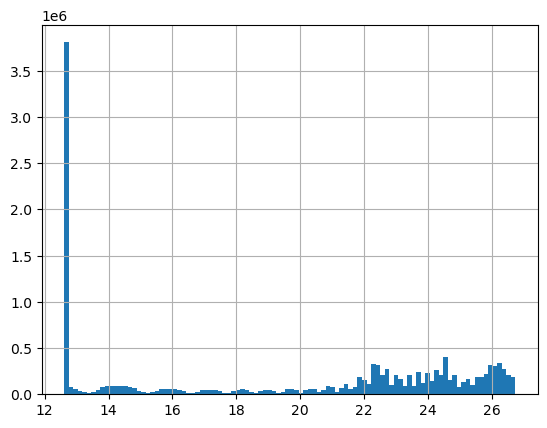

In [18]:
df["f0"].hist(bins=100)

In [19]:
# -----------------------------
# 1. train / test split
# -----------------------------
RANDOM_SEED = 42
TRAIN_SIZE = 300_000
TEST_SIZE = 300_000

rng = np.random.default_rng(RANDOM_SEED)
idx = rng.permutation(len(df))

train_idx = idx[:TRAIN_SIZE]
test_idx = idx[TRAIN_SIZE:TRAIN_SIZE + TEST_SIZE]

X_train = df.iloc[train_idx][FEATURE_COLS].to_numpy()
T_train = df.iloc[train_idx]["treatment"].to_numpy()
Y_train = df.iloc[train_idx]["visit"].to_numpy()

X_test = df.iloc[test_idx][FEATURE_COLS].to_numpy()
T_test = df.iloc[test_idx]["treatment"].to_numpy()
Y_test = df.iloc[test_idx]["visit"].to_numpy()

print(X_train.shape, T_train.shape, Y_train.shape)
print(X_test.shape, T_test.shape, Y_test.shape)

(300000, 12) (300000,) (300000,)
(300000, 12) (300000,) (300000,)


In [20]:
# -----------------------------
# 2. Causal Forest fit
# -----------------------------
model = fit_causal_forest(
    X_train,
    T_train,
    Y_train
)

/opt/anaconda3/envs/thesis311/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/envs/thesis311/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.ht

In [21]:
# -----------------------------
# 3. CATE prediction
# -----------------------------
cate_test = np.asarray(
    model.effect(X_test)
).reshape(-1)

print("n:", len(cate_test))
print("mean CATE:", cate_test.mean())
print("min CATE:", cate_test.min())
print("max CATE:", cate_test.max())

n: 300000
mean CATE: 0.007659577136575966
min CATE: -0.05449981770623942
max CATE: 0.1868661163836418


In [22]:
# -----------------------------
# 4. Quintile evaluation
# -----------------------------
quintile_results = evaluate_quintiles(
    Y_test,
    T_test,
    cate_test
)

display(quintile_results)

,cate_group,mean_cate,treated_visit_rate,control_visit_rate,observed_uplift
0,Q1,-0.004678,0.023455,0.020578,0.002877
1,Q2,0.000205,0.002004,0.001428,0.000576
2,Q3,0.001403,0.004005,0.004523,-0.000518
3,Q4,0.005250,0.019483,0.016845,0.002638
4,Q5,0.036117,0.191550,0.155059,0.036491
